# Bayesian updating for a coin (Beta–Binomial)

We flip a coin with unknown bias $\theta = P(\text{heads})$.

* Likelihood: $p(y\mid\theta) = \mathrm{Bin}(y\mid n,\theta) = \binom{n}{y}\theta^{y}(1-\theta)^{n-y}$
* Prior: $p(\theta) = \mathrm{Beta}(\theta\mid\alpha,\beta)$
* Posterior (conjugacy): $p(\theta\mid y) = \mathrm{Beta}(\theta\mid \alpha+y,\ \beta+n-y)$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import betaln, comb

rng = np.random.default_rng(42)
theta_grid = np.linspace(0, 1, 1001)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## 1. Choosing non-uniform priors

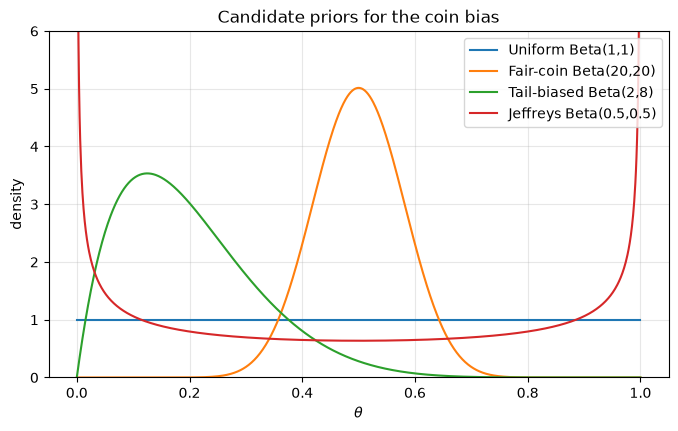

In [3]:
priors = {
    "Uniform Beta(1,1)":        (1, 1),
    "Fair-coin Beta(20,20)":    (20, 20),
    "Tail-biased Beta(2,8)":    (2, 8),
    "Jeffreys Beta(0.5,0.5)":   (0.5, 0.5),
}

for name, (a, b) in priors.items():
    plt.plot(theta_grid, stats.beta.pdf(theta_grid, a, b), label=name)
plt.ylim(0, 6); plt.xlabel(r"$\theta$"); plt.ylabel("density")
plt.title("Candidate priors for the coin bias"); plt.legend(); plt.show()

## Experiment

The *true* bias is known only to the simulator. 

In [5]:
THETA_TRUE = 0.5      
N_FLIPS    = 500
ALPHA, BETA = 2, 8    

flips = rng.binomial(1, THETA_TRUE, size=N_FLIPS)   
print("first 20 flips:", flips[:20])
print(f"heads = {flips.sum()} / {N_FLIPS}")

first 20 flips: [1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1]
heads = 246 / 500


## Prior updating

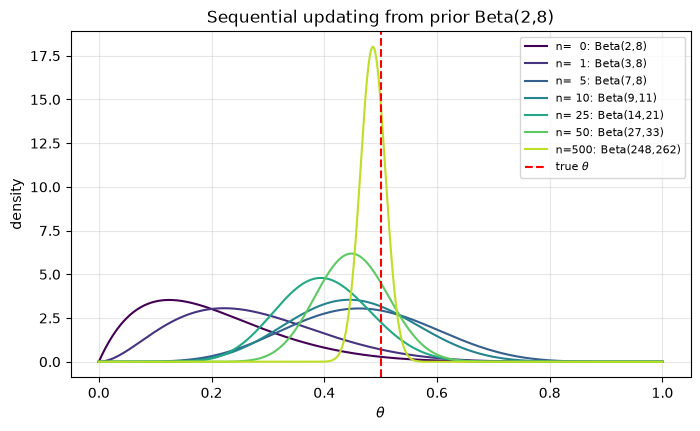

In [6]:
checkpoints = [0, 1, 5, 10, 25, 50, 500]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(checkpoints)))

for n, c in zip(checkpoints, colors):
    h = flips[:n].sum()
    a_n, b_n = ALPHA + h, BETA + (n - h)
    plt.plot(theta_grid, stats.beta.pdf(theta_grid, a_n, b_n), color=c,
             label=f"n={n:3d}: Beta({a_n:g},{b_n:g})")
plt.axvline(THETA_TRUE, color="red", ls="--", label=r"true $\theta$")
plt.xlabel(r"$\theta$"); plt.ylabel("density")
plt.title(f"Sequential updating from prior Beta({ALPHA},{BETA})")
plt.legend(fontsize=8); plt.show()

## Posterior mean and credible interval vs. number of flips

$$\mathbb{E}[\theta\mid y] = \frac{\alpha+y}{\alpha+\beta+n}
= \underbrace{\frac{\alpha+\beta}{\alpha+\beta+n}}_{w}\,\frac{\alpha}{\alpha+\beta} + (1-w)\,\frac{y}{n}$$

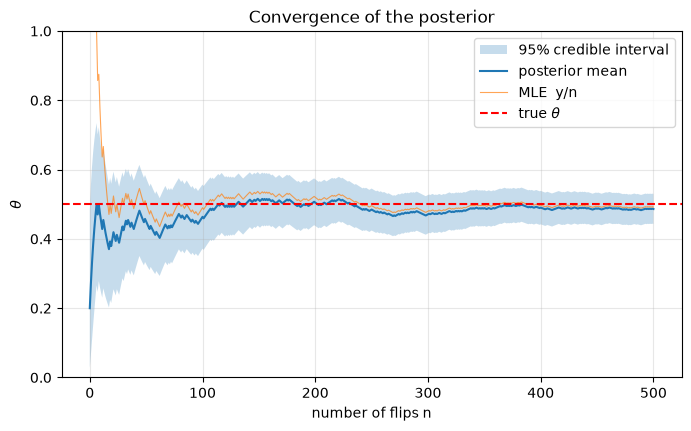

In [7]:
ns = np.arange(0, N_FLIPS + 1)
heads_cum = np.concatenate([[0], np.cumsum(flips)])
a_n, b_n = ALPHA + heads_cum, BETA + (ns - heads_cum)

post_mean = a_n / (a_n + b_n)
lo, hi = stats.beta.ppf(0.025, a_n, b_n), stats.beta.ppf(0.975, a_n, b_n)
mle = np.where(ns > 0, heads_cum / np.maximum(ns, 1), np.nan)

plt.fill_between(ns, lo, hi, alpha=0.25, label="95% credible interval")
plt.plot(ns, post_mean, label="posterior mean")
plt.plot(ns, mle, lw=0.8, alpha=0.7, label="MLE  y/n")
plt.axhline(THETA_TRUE, color="red", ls="--", label=r"true $\theta$")
plt.xlabel("number of flips n"); plt.ylabel(r"$\theta$"); plt.ylim(0, 1)
plt.title("Convergence of the posterior"); plt.legend(); plt.show()

## Same data, different priors

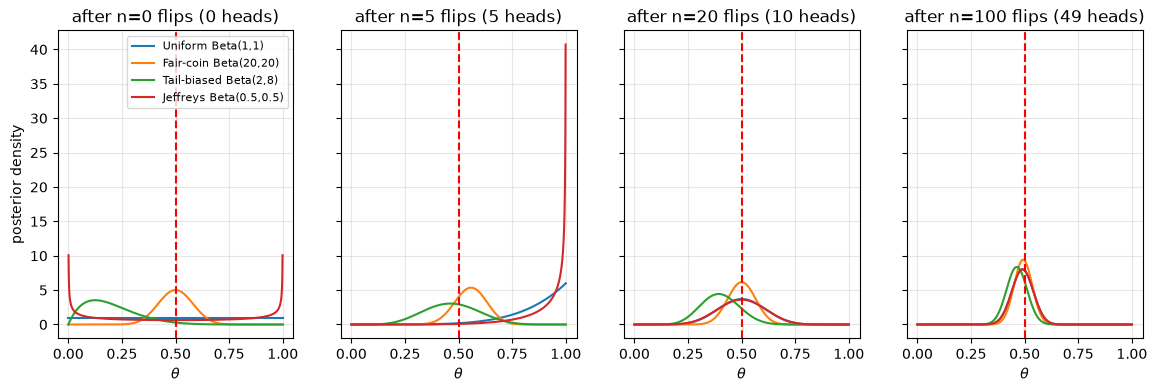

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
for ax, n in zip(axes, [0, 5, 20, 100]):
    h = flips[:n].sum()
    for name, (a, b) in priors.items():
        ax.plot(theta_grid, stats.beta.pdf(theta_grid, a + h, b + n - h), label=name)
    ax.axvline(THETA_TRUE, color="red", ls="--")
    ax.set_title(f"after n={n} flips ({h} heads)"); ax.set_xlabel(r"$\theta$")
axes[0].set_ylabel("posterior density"); axes[0].legend(fontsize=8); plt.show()

## Posterior predictive

From the notes:
$$p(\tilde y\mid y) = \binom{\tilde n}{\tilde y}\frac{B(\tilde y + y + \alpha,\ \beta + n + \tilde n - y - \tilde y)}{B(y+\alpha,\ \beta+n-y)}$$
With $y=4$, $n=5$, $\alpha=\beta=1$ this becomes $\binom{\tilde n}{\tilde y}\,B(\tilde y+5,\tilde n-\tilde y+2)/B(5,2)$. We compare it with the naive *plug-in* prediction $\mathrm{Bin}(\tilde n, \hat\theta)$ using $\hat\theta = y/n = 0.8$.

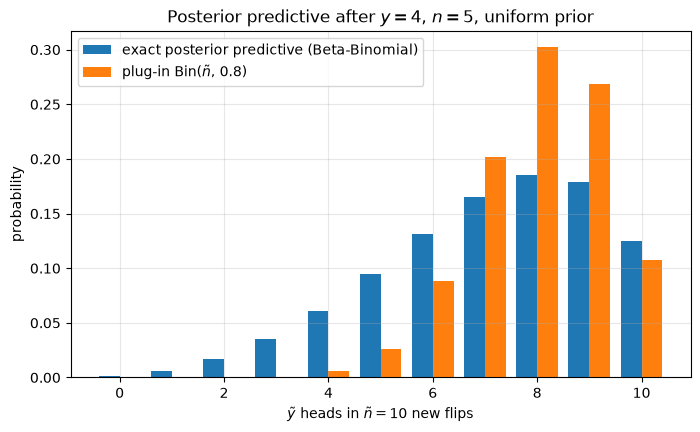

sum of exact pmf: 1.0
E[y~|y]  exact = 7.143   (= n~ * E[theta|y] = 7.143)
Var[y~|y] exact = 4.337   plug-in = 1.600


In [9]:
def post_pred(yt, nt, y, n, a, b):
    return comb(nt, yt) * np.exp(betaln(yt + y + a, b + n + nt - y - yt) - betaln(y + a, b + n - y))

y_obs, n_obs, a0, b0, n_new = 4, 5, 1, 1, 10
yt = np.arange(n_new + 1)
exact = post_pred(yt, n_new, y_obs, n_obs, a0, b0)

plug_in = stats.binom.pmf(yt, n_new, y_obs / n_obs)  

w = 0.4
plt.bar(yt - w/2, exact, w, label="exact posterior predictive (Beta-Binomial)")
plt.bar(yt + w/2, plug_in, w, label=r"plug-in Bin($\tilde n$, 0.8)")
plt.xlabel(r"$\tilde y$ heads in $\tilde n=10$ new flips"); plt.ylabel("probability")
plt.title(r"Posterior predictive after $y=4$, $n=5$, uniform prior"); plt.legend(); plt.show()
print("sum of exact pmf:", exact.sum().round(6))
print(f"E[y~|y]  exact = {np.sum(yt*exact):.3f}   (= n~ * E[theta|y] = {n_new*(y_obs+a0)/(a0+b0+n_obs):.3f})")
print(f"Var[y~|y] exact = {np.sum(yt**2*exact) - np.sum(yt*exact)**2:.3f}   plug-in = {n_new*0.8*0.2:.3f}")

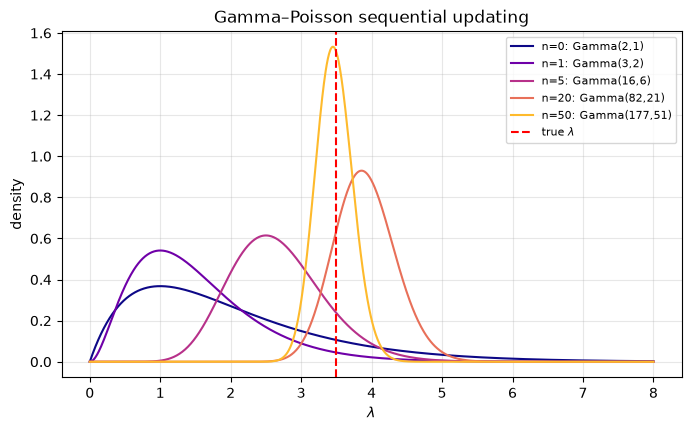

In [10]:
LAMBDA_TRUE = 3.5
A0, B0 = 2.0, 1.0            
counts = rng.poisson(LAMBDA_TRUE, size=50)
lam = np.linspace(0, 8, 1000)

for n, c in zip([0, 1, 5, 20, 50], plt.cm.plasma(np.linspace(0, 0.85, 5))):
    a_n, b_n = A0 + counts[:n].sum(), B0 + n
    plt.plot(lam, stats.gamma.pdf(lam, a_n, scale=1 / b_n), color=c,
             label=f"n={n}: Gamma({a_n:g},{b_n:g})")
plt.axvline(LAMBDA_TRUE, color="red", ls="--", label=r"true $\lambda$")
plt.xlabel(r"$\lambda$"); plt.ylabel("density")
plt.title("Gamma–Poisson sequential updating"); plt.legend(fontsize=8); plt.show()